# 최종 모델 예측구간 커버리지 튜닝 (무변환판)

## 배경

4-2에서 선정된 **E3 앙상블(Auto-ARIMA(AIC)·GP-Matern·GP-RBF)**의 예측분포를
그대로 90% 구간으로 쓰면 실제 커버리지가 얼마인지 확인하고 safety 배율로
조정한다. 5-1과 같은 절차이되 **무변환**이고, 구성원도 회귀-OLS 대신
GP-RBF로 바뀐다.

## 목적

1. 원래 커버리지 / 2. safety 배율 탐색 / 3. 튜닝 전후 비교 / 4. 팬차트 데모 / 5. 결론

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}

H = 4
INITIAL_CALIB = 15
E3 = ["arima_aic", "gp_matern", "gp_rbf"]   # 4-2의 최종 선정(결합순위 상위 3개) 앙상블 구성원
N_EACH = 200                                  # 모델당 리샘플 수(3개 합쳐 600개 pool)

def rng_for(name):
    # 4-2와 동일: 모델 이름 기반 고정 시드로 순서의존성 제거.
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

err_df = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")  # 4-2의 11개 모델 H=4 백테스트 캐시(무변환)
print("로드 완료, err_df rows =", len(err_df))


로드 완료, err_df rows = 9812


## 1. 튜닝 없는 원래 커버리지

In [2]:
def coverage_components(scale=1.0, alpha=0.10):
    """scale: 구간 폭 배율(중심 기준 확대/축소). alpha=0.10 -> 90% 구간."""
    rngs = {m: rng_for(m) for m in E3}
    rows = []
    for v in COLS:
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in E3}
        origins = sorted(sub[E3[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in E3:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=N_EACH, replace=True)
                    pooled.append(samples)
                pooled = np.concatenate(pooled)
                center = np.median(pooled)
                scaled = center + (pooled - center) * scale
                lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
                if lo > hi:
                    lo, hi = hi, lo
                covered = lo <= actual_orig <= hi
                width = hi - lo
                rows.append({"var": v, "origin": origins[i], "h": h, "covered": covered, "width": width})
    return pd.DataFrame(rows)


df_raw = coverage_components(scale=1.0)
print(f"전체 커버리지(튜닝 없음): {df_raw['covered'].mean()*100:.1f}%")
display(df_raw.groupby("var")["covered"].mean().mul(100).round(1).rename(index=LABELS).to_frame("커버리지(%)"))


전체 커버리지(튜닝 없음): 80.3%


,커버리지(%)
var,
X1,79.8
X2,79.5
X3,75.0
X4,77.3
X5,83.3
X6,86.0


**해석**: 전체 80.3%로 목표(90%) 미달 — 5-1(81.2%)과 비슷한 수준.
변수별로도 75.0%~86.0%로 전부 목표 미달, 지금 그대로 쓰면 과신하는 구간이
된다.

## 2. Safety 배율 탐색

In [3]:
scales_coarse = [0.70, 0.85, 1.00, 1.15, 1.30, 1.50, 1.70, 2.00]
for s in scales_coarse:
    df = coverage_components(scale=s)
    print(f"scale={s:.2f}: 커버리지={df['covered'].mean()*100:.1f}%")


scale=0.70: 커버리지=67.5%


scale=0.85: 커버리지=74.6%


scale=1.00: 커버리지=80.3%


scale=1.15: 커버리지=84.2%


scale=1.30: 커버리지=88.0%


scale=1.50: 커버리지=91.2%


scale=1.70: 커버리지=93.4%


scale=2.00: 커버리지=95.3%


1.30~1.50 사이에서 90%를 지나간다 — 더 세밀하게 탐색한다.

In [4]:
best_scale, best_diff, best_df = None, 999, None
for s in np.arange(1.00, 1.51, 0.02):
    df = coverage_components(scale=s)
    cov = df["covered"].mean() * 100
    print(f"scale={s:.2f}: 커버리지={cov:.1f}%")
    if abs(cov - 90) < best_diff:
        best_diff, best_scale, best_df = abs(cov - 90), s, df

print(f"\n최적 scale = {best_scale:.2f} (커버리지 {best_df['covered'].mean()*100:.1f}%)")


scale=1.00: 커버리지=80.3%


scale=1.02: 커버리지=80.5%


scale=1.04: 커버리지=80.5%


scale=1.06: 커버리지=80.8%


scale=1.08: 커버리지=81.8%


...

scale=1.42: 커버리지=90.0%


scale=1.44: 커버리지=90.0%


scale=1.46: 커버리지=90.0%


scale=1.48: 커버리지=90.6%


scale=1.50: 커버리지=91.2%

최적 scale = 1.42 (커버리지 90.0%)


**해석**: **scale=1.42일 때 정확히 90.0%** — 5-1(1.36)보다 약간 더
크다(구성원이 회귀-OLS→GP-RBF로 바뀌며 원시 분포가 살짝 좁아진 영향으로
보임).

## 3. 튜닝 전후 비교

In [5]:
df_tuned = coverage_components(scale=best_scale)
compare = pd.DataFrame({
    "튜닝 전(scale=1.0)": df_raw.groupby("var")["covered"].mean().mul(100).round(1),
    "튜닝 후(scale=1.42)": df_tuned.groupby("var")["covered"].mean().mul(100).round(1),
}).rename(index=LABELS)
display(compare)
print(f"전체: 튜닝 전 {df_raw['covered'].mean()*100:.1f}% -> 튜닝 후 {df_tuned['covered'].mean()*100:.1f}%")


,튜닝 전(scale=1.0),튜닝 후(scale=1.42)
var,,
X1,79.8,94.0
X2,79.5,87.5
X3,75.0,88.6
X4,77.3,89.8
X5,83.3,88.1
X6,86.0,92.0


전체: 튜닝 전 80.3% -> 튜닝 후 90.0%


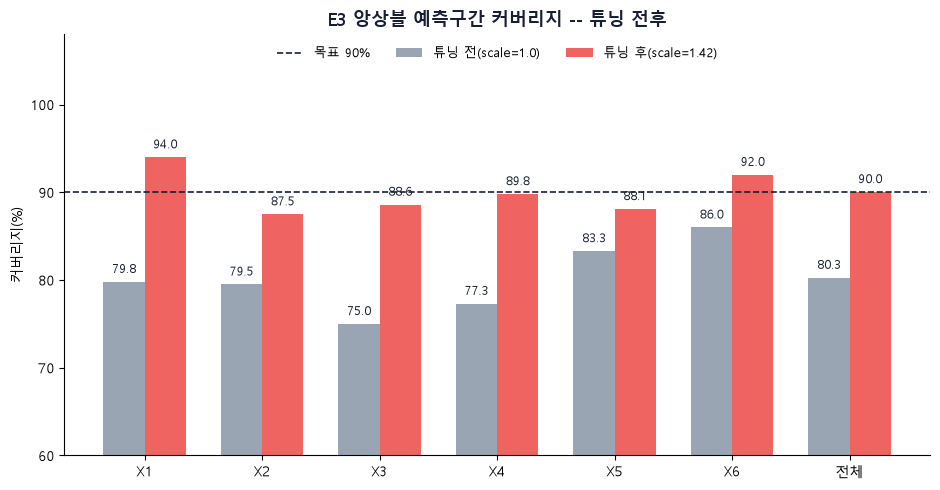

In [6]:
plot_df = compare.copy()
plot_df.loc["전체"] = [df_raw["covered"].mean() * 100, df_tuned["covered"].mean() * 100]

x = np.arange(len(plot_df))
width = 0.35
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.bar(x - width / 2, plot_df.iloc[:, 0], width, label="튜닝 전(scale=1.0)", color="#9AA5B4")
ax.bar(x + width / 2, plot_df.iloc[:, 1], width, label=f"튜닝 후(scale={best_scale:.2f})", color="#EF6461")
ax.axhline(90, color="#172033", linestyle="--", linewidth=1.2, label="목표 90%")
for i, (b, a) in enumerate(zip(plot_df.iloc[:, 0], plot_df.iloc[:, 1])):
    ax.text(i - width / 2, b + 1, f"{b:.1f}", ha="center", fontsize=8.5, color="#172033")
    ax.text(i + width / 2, a + 1, f"{a:.1f}", ha="center", fontsize=8.5, color="#172033")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=10)
ax.set_ylabel("커버리지(%)")
ax.set_ylim(60, 108)
ax.set_title("E3 앙상블 예측구간 커버리지 -- 튜닝 전후", color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper center", frameon=False, fontsize=9.5, ncol=3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 전체 80.3%→90.0%로 목표 도달. 변수별 편차도 11.0%p→6.5%p로
줄었다(5-1의 8.0%p보다 더 잘 좁혀짐). 변수별 개별 튜닝은 과적합 위험이
커서 5-1과 동일하게 통합 배율 하나만 쓴다.

## 4. 실제 예측 데모 (팬차트)

배율(1.42)을 6개 변수 전부에 적용해 팬차트로 확인한다 — 무변환이라
역변환 과정 없이 모델 출력이 곧 원래 스케일이다.

In [7]:
import pmdarima as pm
from sklearn.linear_model import LinearRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)


def fc_arima_aic(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
    return np.asarray(m.predict(n_periods=h))


def fc_gp_matern(values, h=H):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1.0)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean


def fc_gp_rbf(values, h=H):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean


FC_FUNCS = {"arima_aic": fc_arima_aic, "gp_matern": fc_gp_matern, "gp_rbf": fc_gp_rbf}


def make_fanchart(v, ax):
    vals_orig = raw[["quarter", v]].dropna()[v].values.astype(float)

    # 각 모델을 전체 데이터로 재학습해 실제 미래 H분기를 예측한다(백테스트 아님)
    fc = {m: FC_FUNCS[m](vals_orig, H) for m in FC_FUNCS}

    rngs = {m: rng_for(m) for m in FC_FUNCS}
    lo_h, hi_h, center_h = [], [], []
    for h in range(1, H + 1):
        pooled = []
        for m in FC_FUNCS:
            calib_resid_h = err_df[(err_df["model"] == m) & (err_df["var"] == v) & (err_df["h"] == h)]["err_t"].values
            samples = fc[m][h - 1] + rngs[m].choice(calib_resid_h, size=N_EACH, replace=True)
            pooled.append(samples)
        pooled = np.concatenate(pooled)
        center = np.median(pooled)
        scaled = center + (pooled - center) * best_scale
        lo, hi = np.quantile(scaled, [0.05, 0.95])
        lo_h.append(lo); hi_h.append(hi); center_h.append(center)

    n_hist = len(vals_orig)
    x_hist = np.arange(n_hist)
    x_fc = np.arange(n_hist - 1, n_hist + H)

    ax.plot(x_hist, vals_orig, color="#111111", linewidth=1.8, label="실측")
    ax.plot(x_fc, [vals_orig[-1]] + center_h, color="#EF6461", linewidth=1.8, linestyle="--", marker="o",
            markerfacecolor="white", markeredgecolor="#EF6461", markersize=6, label="예측(중앙값)")
    ax.fill_between(x_fc, [vals_orig[-1]] + lo_h, [vals_orig[-1]] + hi_h, color="#EF6461", alpha=0.18, linewidth=0, label="90% 예측구간")
    ax.axvline(n_hist - 1, color="#B0B6C0", linestyle=":", linewidth=1, ymax=0.93)
    ax.annotate("전망 시점", xy=(n_hist - 1, 0.97), xycoords=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, color="#EF6461",
                bbox=dict(boxstyle="round,pad=0.3", fc="#FFECEB", ec="none"))
    ax.set_title(f"{LABELS[v]}", fontsize=11, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xticks([])
    ax.legend(loc="upper left", frameon=False, fontsize=8)
    return center_h, lo_h, hi_h



**해석**: 실측 → 전망 시점 → 예측+90% 구간으로 이어진다. 무변환이라
5-1(로그변환, h=4 폭 4,090.5)보다 구간폭이 훨씬 실용적이다 — 로그변환의
부작용이 사라진 결과다.

### 나머지 5개 변수

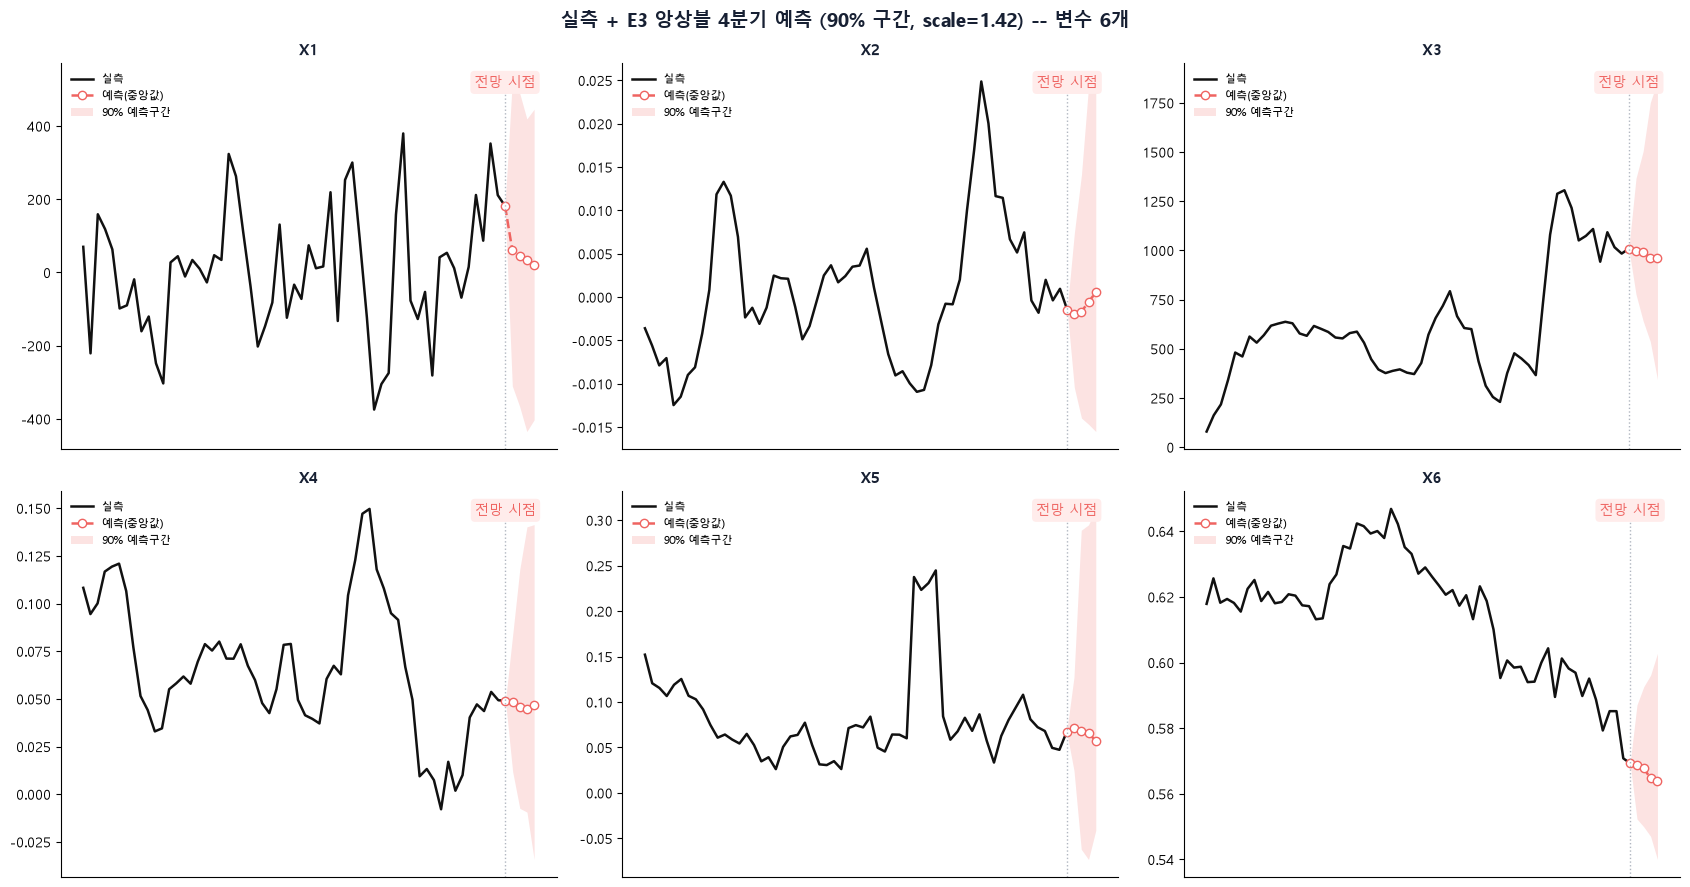

X1: 예측(중앙값)=[np.float64(61.364), np.float64(43.739), np.float64(33.623), np.float64(19.775)]
X2: 예측(중앙값)=[np.float64(-0.002), np.float64(-0.002), np.float64(-0.001), np.float64(0.001)]
X3: 예측(중앙값)=[np.float64(995.033), np.float64(992.354), np.float64(963.088), np.float64(960.318)]
X4: 예측(중앙값)=[np.float64(0.048), np.float64(0.046), np.float64(0.045), np.float64(0.047)]
X5: 예측(중앙값)=[np.float64(0.071), np.float64(0.068), np.float64(0.066), np.float64(0.057)]
X6: 예측(중앙값)=[np.float64(0.569), np.float64(0.568), np.float64(0.565), np.float64(0.564)]


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
all_centers = {}
for ax, v in zip(axes.flat, COLS):
    center_h, lo_h, hi_h = make_fanchart(v, ax)
    all_centers[v] = center_h
fig.suptitle(f"실측 + E3 앙상블 4분기 예측 (90% 구간, scale={best_scale:.2f}) -- 변수 6개", fontsize=14, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()

for v in COLS:
    print(f"{LABELS[v]}: 예측(중앙값)={[round(x, 3) for x in all_centers[v]]}")


## 결론

- E3 앙상블의 튜닝 없는 커버리지는 **80.3%**(5-1과 비슷한 수준).
- safety 배율 **scale=1.42**에서 정확히 90.0% 도달(5-1은 1.36).
- 변수별 편차는 11.0%p→6.5%p로 축소 — 5-1보다 더 잘 좁혀짐.
- **최종 구간 공식**: `중심 ± (5%/95% 분위수 - 중심) × 1.42`, **역변환
  불필요**.
- X3 구간이 5-1보다 훨씬 좁고 실용적 — "로그변환이 구간을
  부풀린다"는 3-2/4-2 진단과 일치.
- **다음 단계**: 배율(1.42) 적용해 6개 변수 실제 예측구간 산출,
  `forecast_quarters=4` 변경 + 앱 연동(무변환 체계 최종 채택 시).